In [1]:
import torch
from torch.utils.data import DataLoader

from deep_models.vae import ConvVAE, plot_latent_usage
from deep_models.vae_train import *
from deep_models.data import load_folds, make_splits, S00MILDataset

In [2]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 7

In [3]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
device = torch.device("cuda")

train=1085  val=132  test=136


In [4]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True, return_cond=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False, return_cond=True)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

In [5]:
model = ConvVAE(latent=64, cond_dim=2).to(device)  # match your training args
state_dict = torch.load(f"best_cvae_fold{split_k}.pt", map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(5, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=66, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=66, out_features=64, bias=True)
  (fc): Linear(in_features=66, out_features=64, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 5, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
)

In [6]:
val_mu, val_logvar, val_y = encode_bags(model, val_loader, device)

active units: 59/64   total KL: 74.9 nats


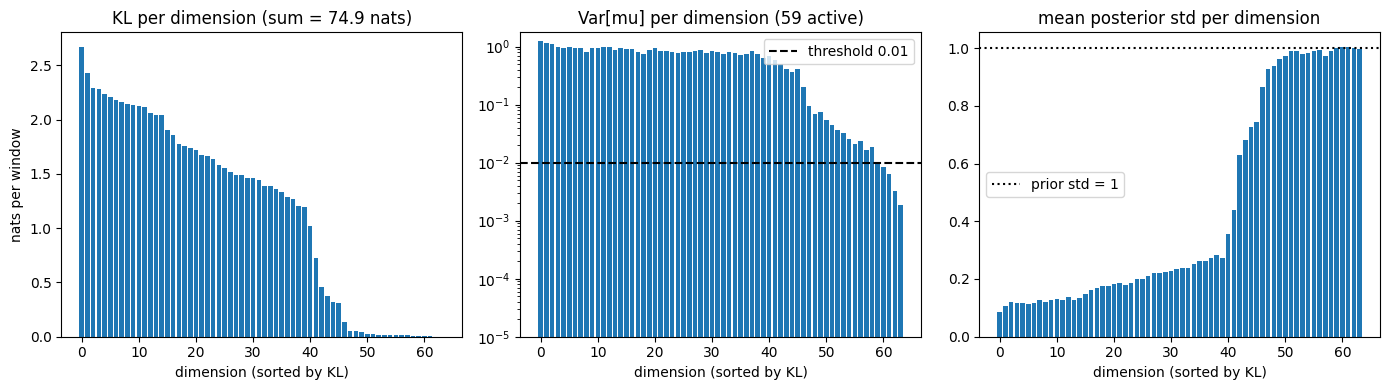

In [7]:
fig, order, n_active = plot_latent_usage(val_mu, val_logvar, thr=0.01)

# See how well it reconstructs

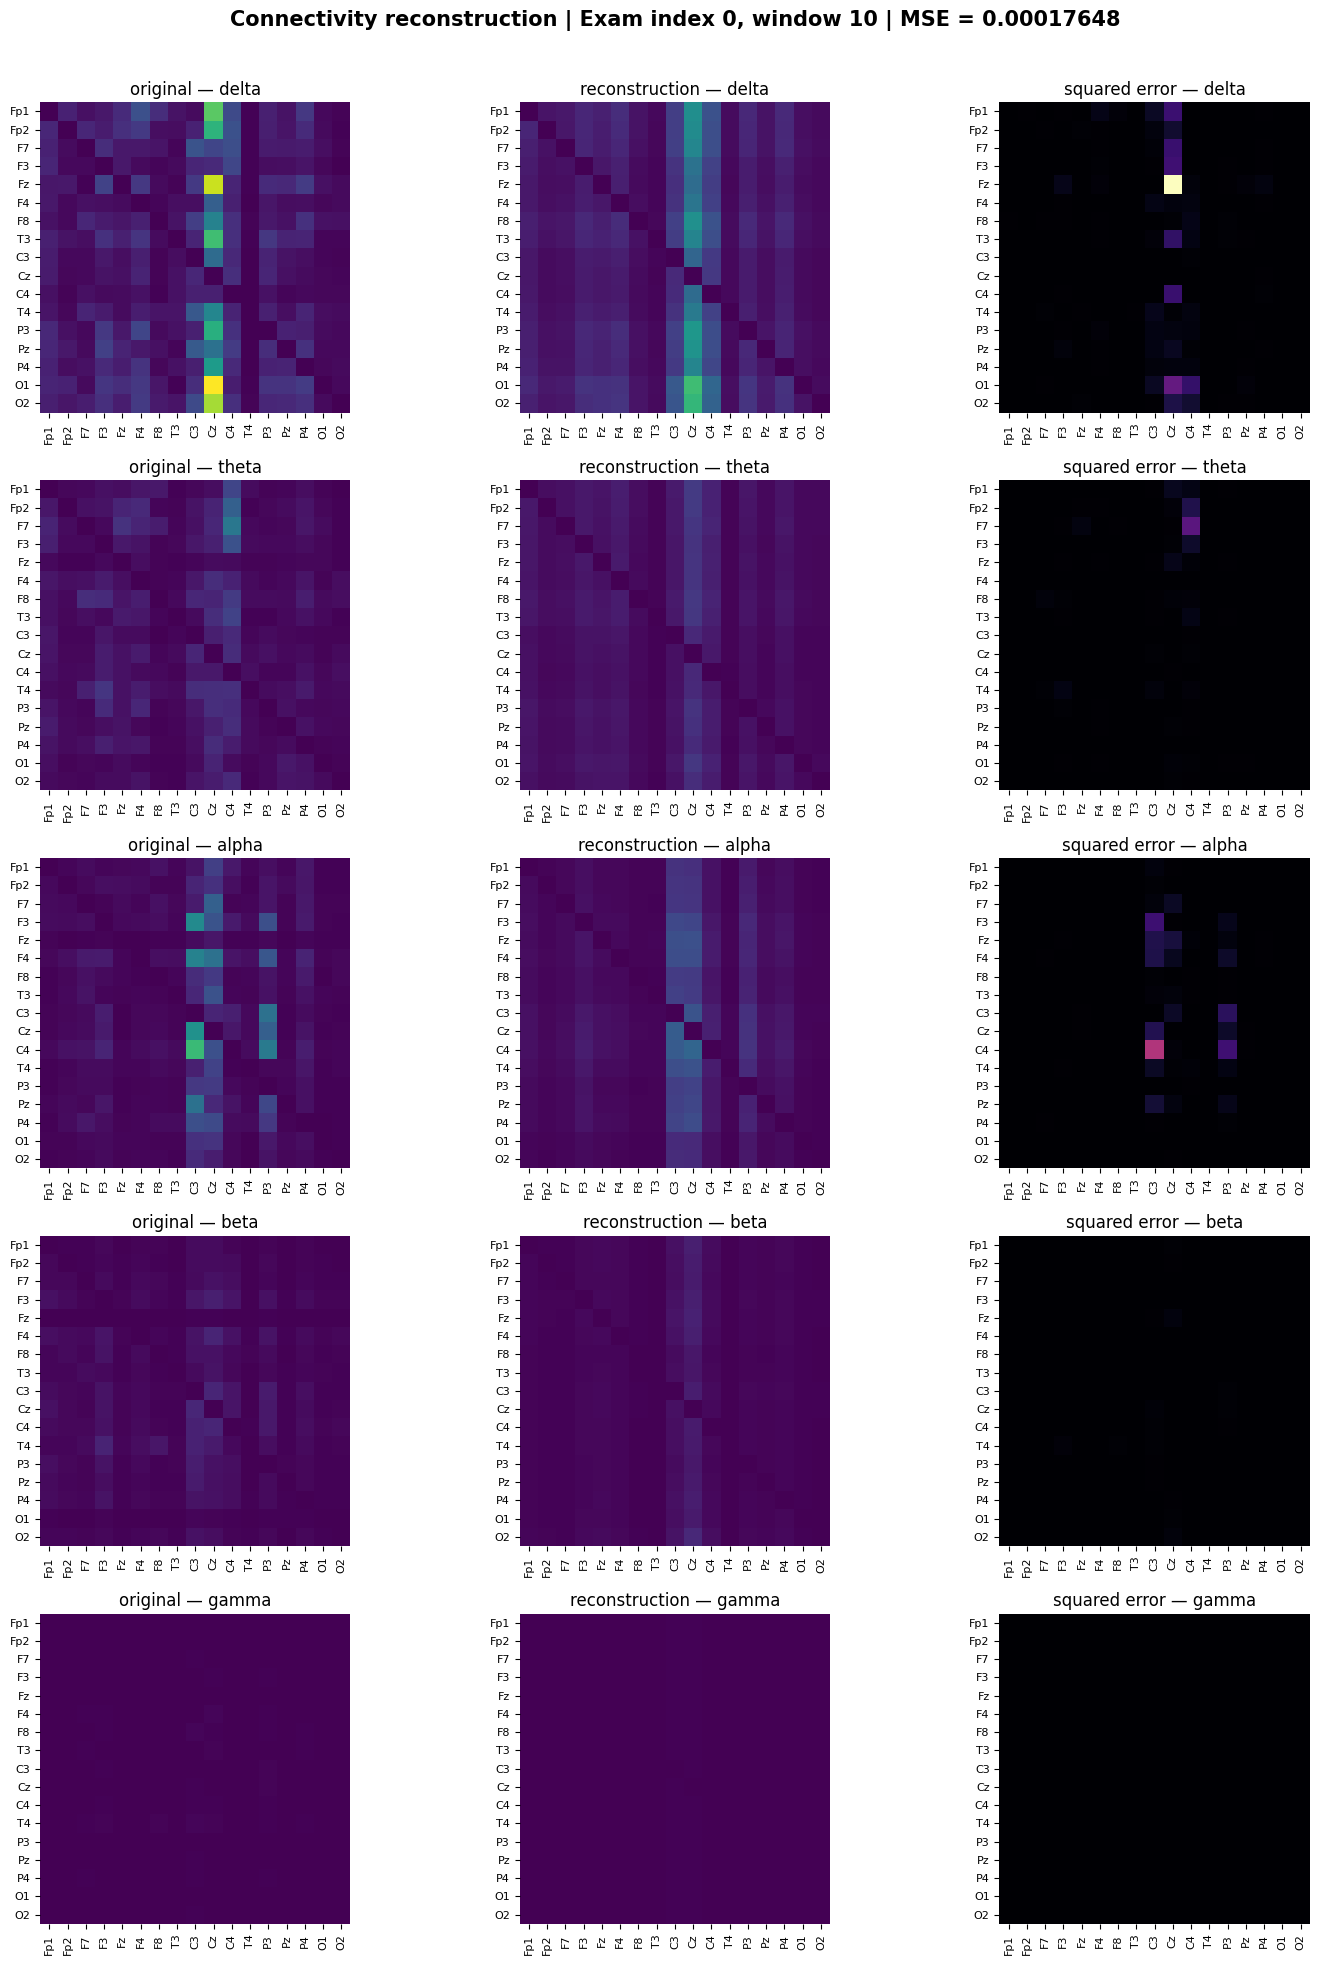

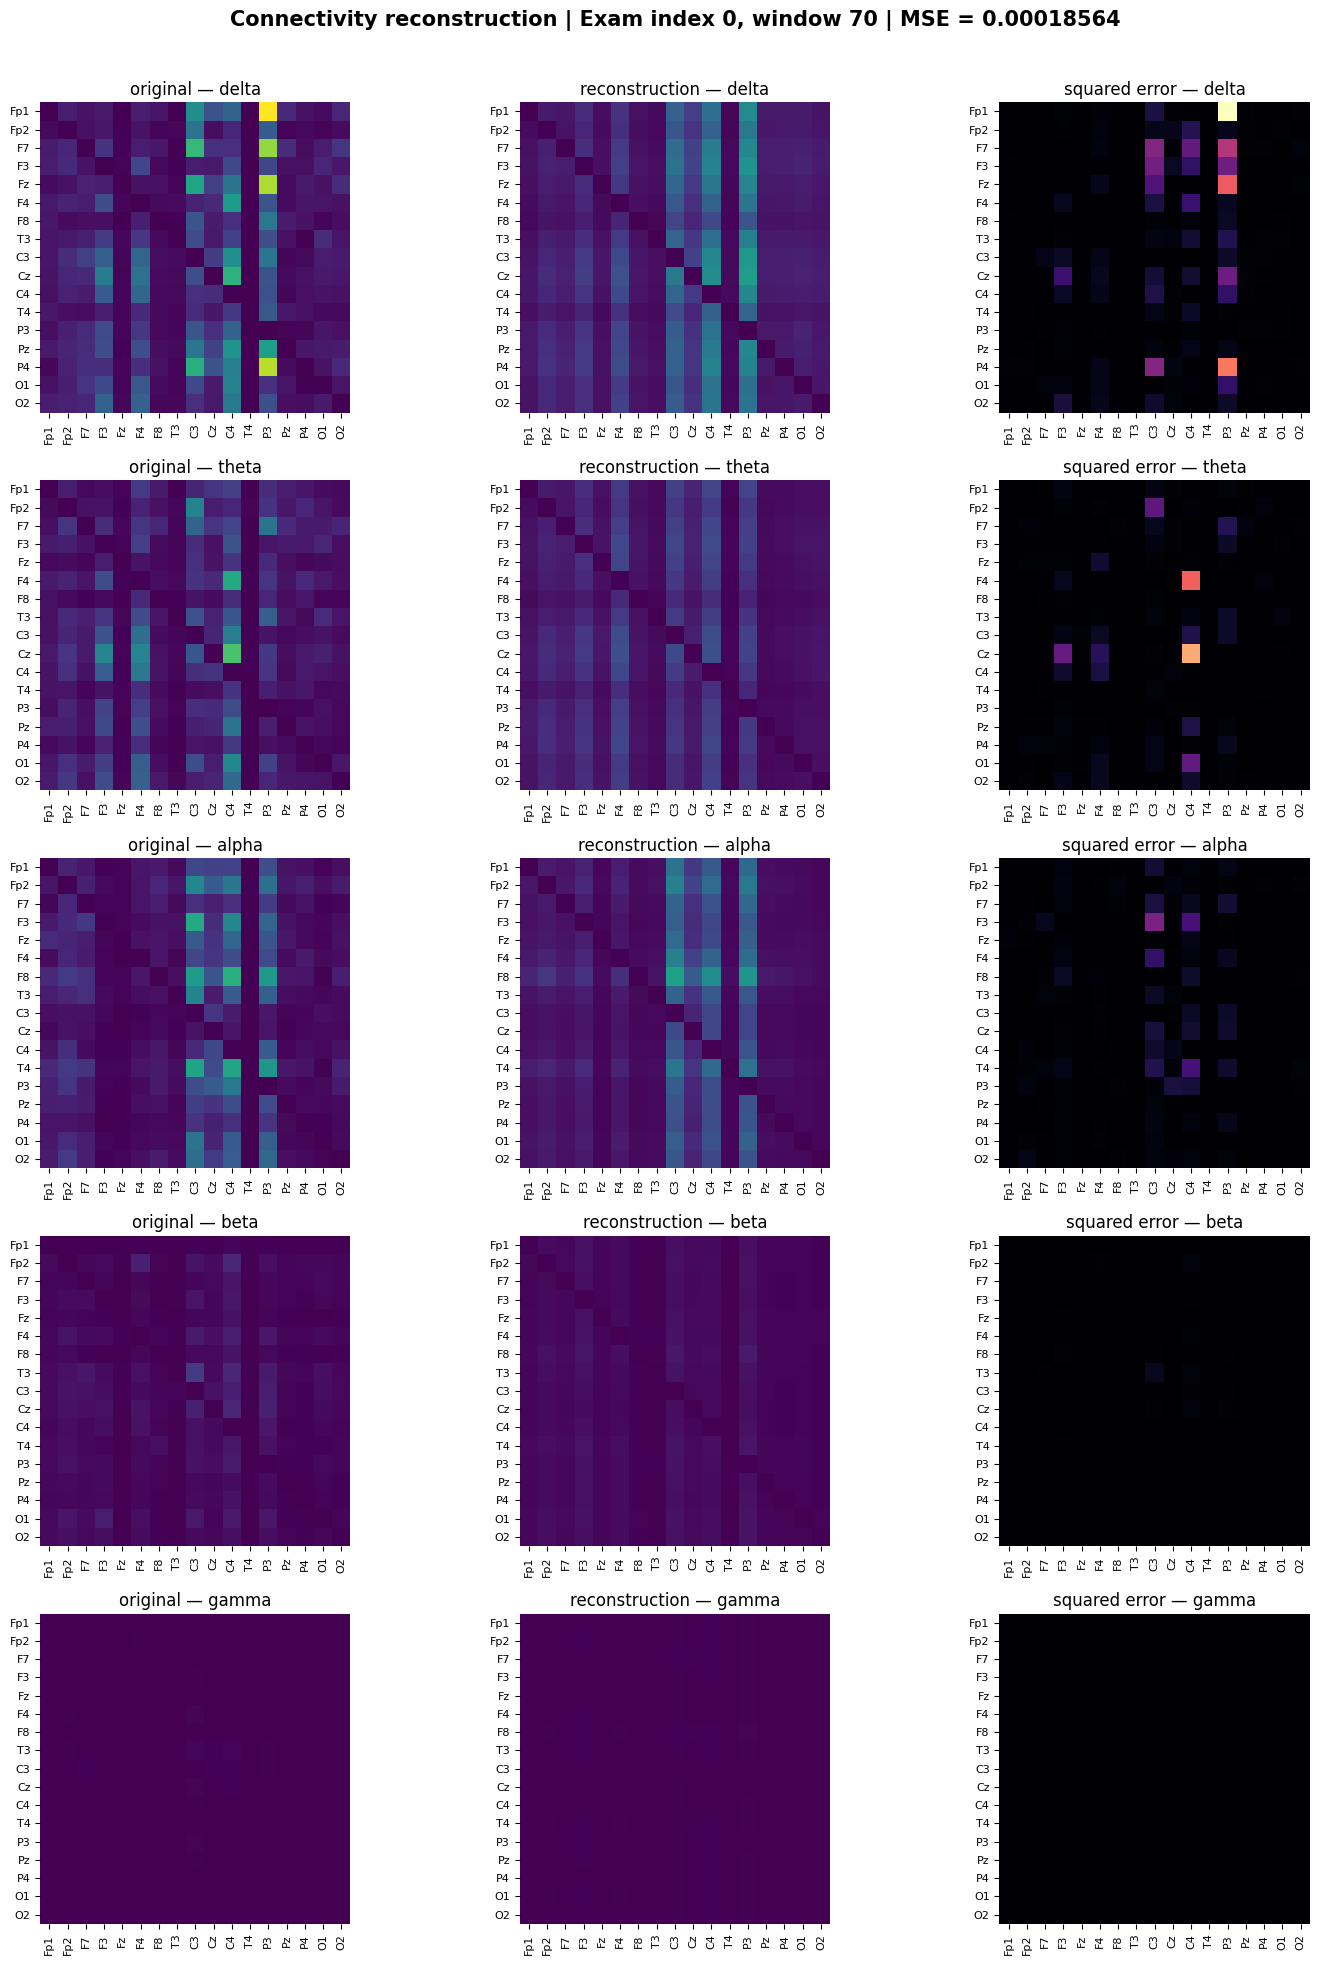

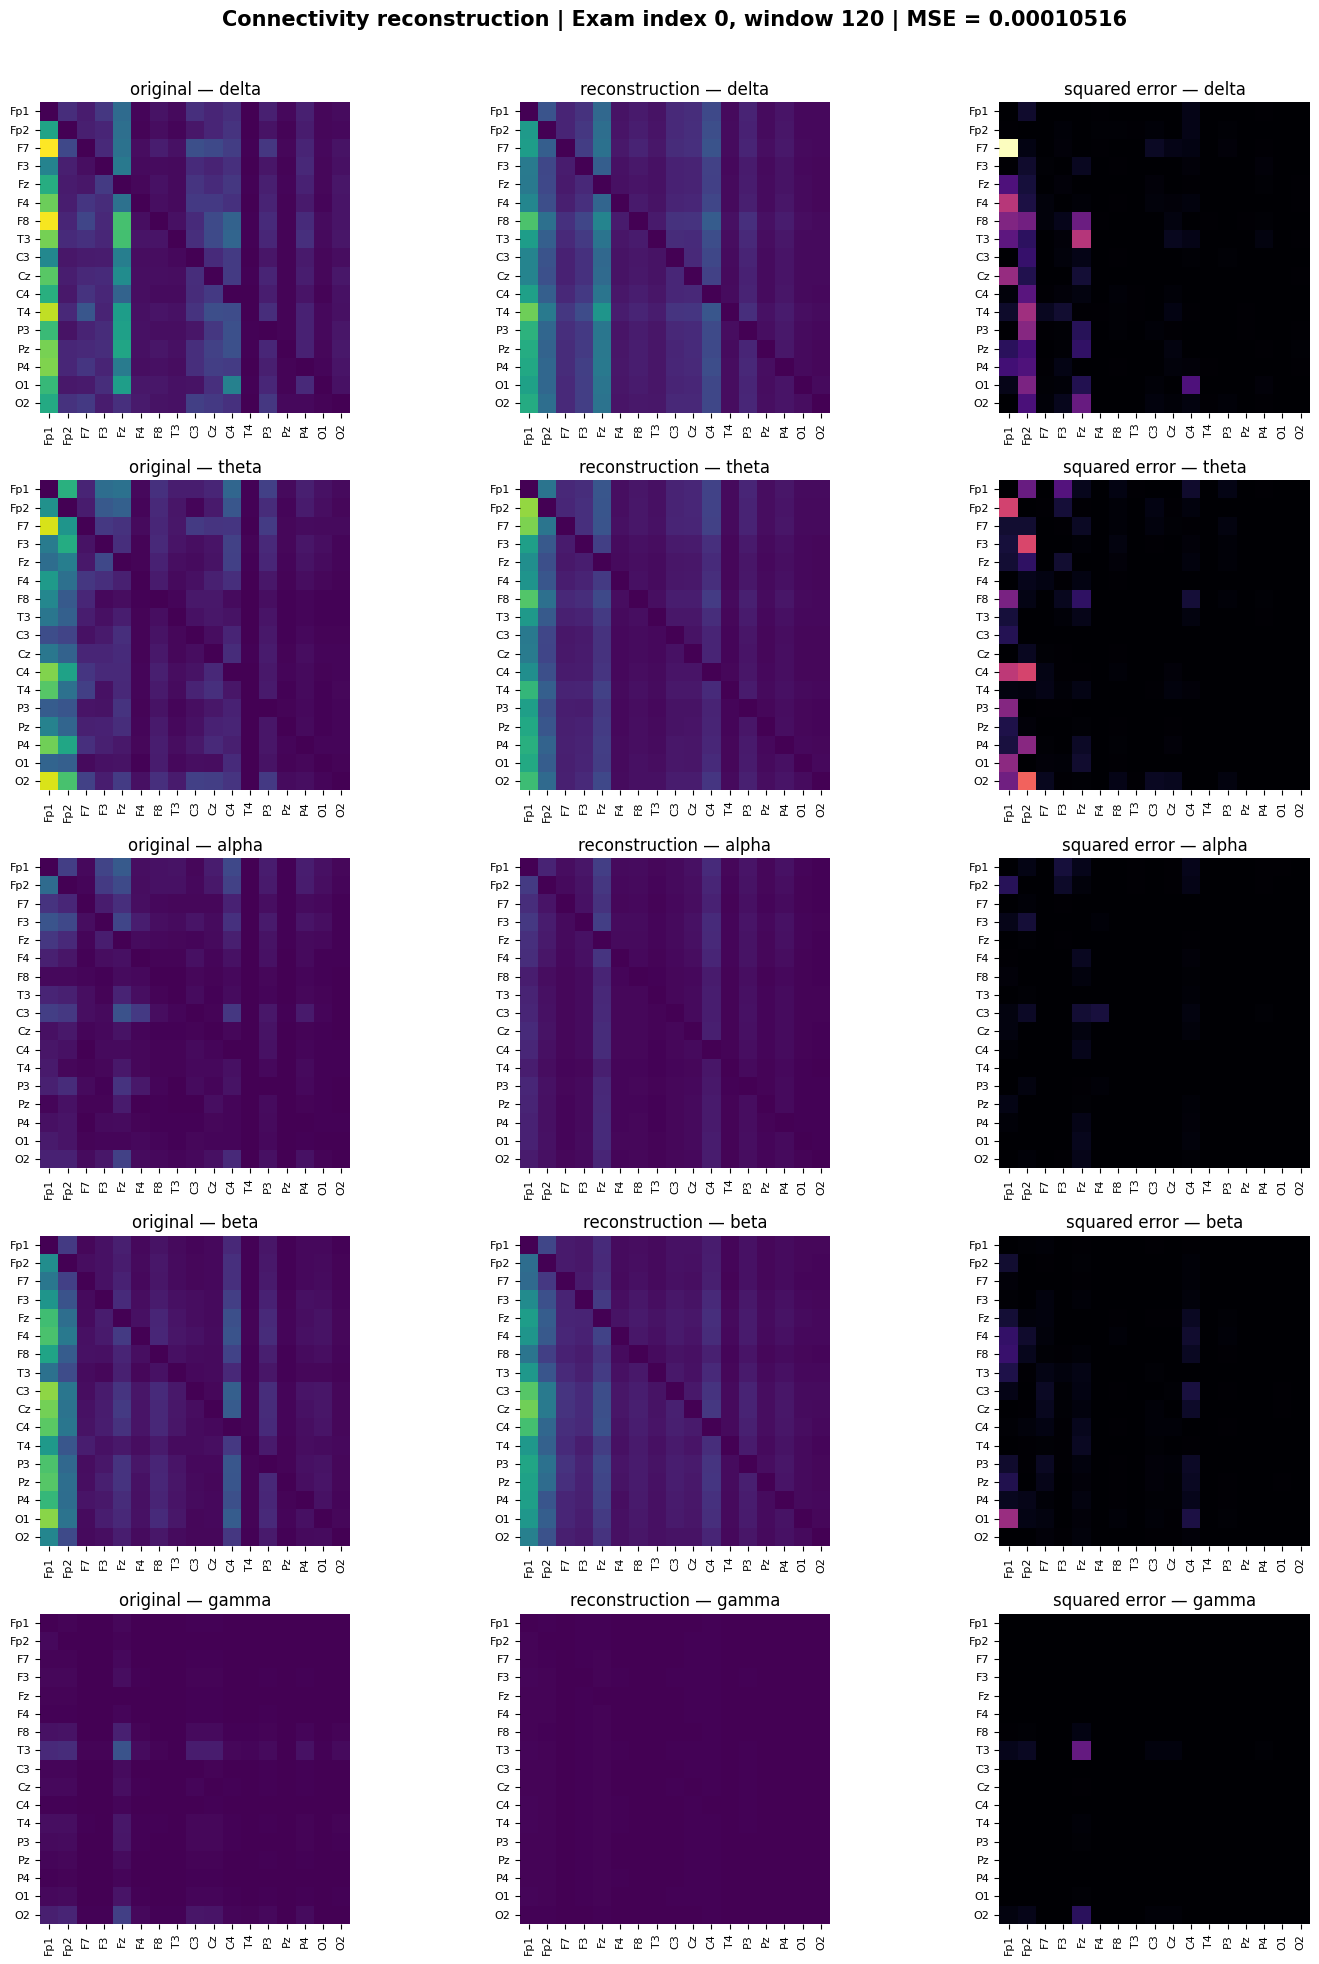

In [8]:
plot_reconstructions(model, val_loader, device, exam_idx=0, window_indices=(10, 70, 120))

# How does the latent space look?

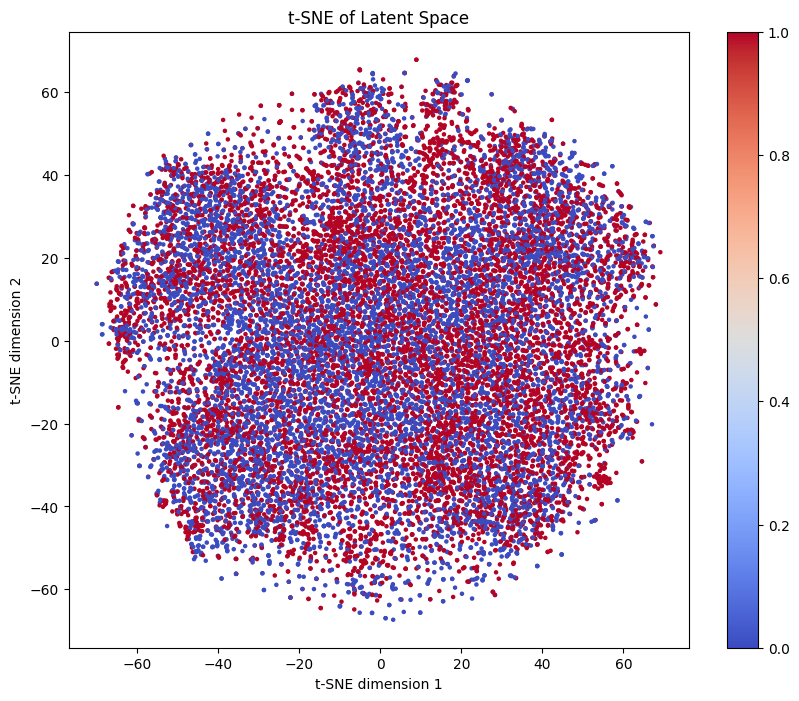

In [9]:
g = plot_tsne(val_mu, val_y)
g.show()

# Test out the generative skill

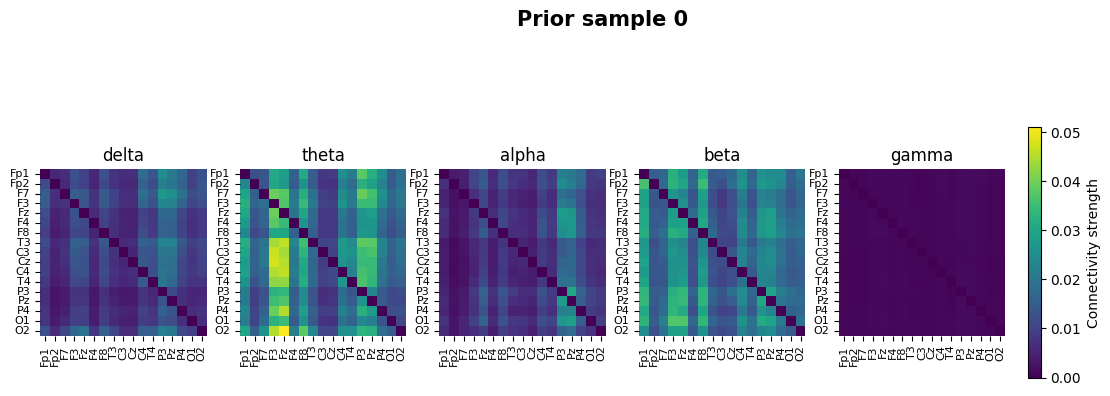

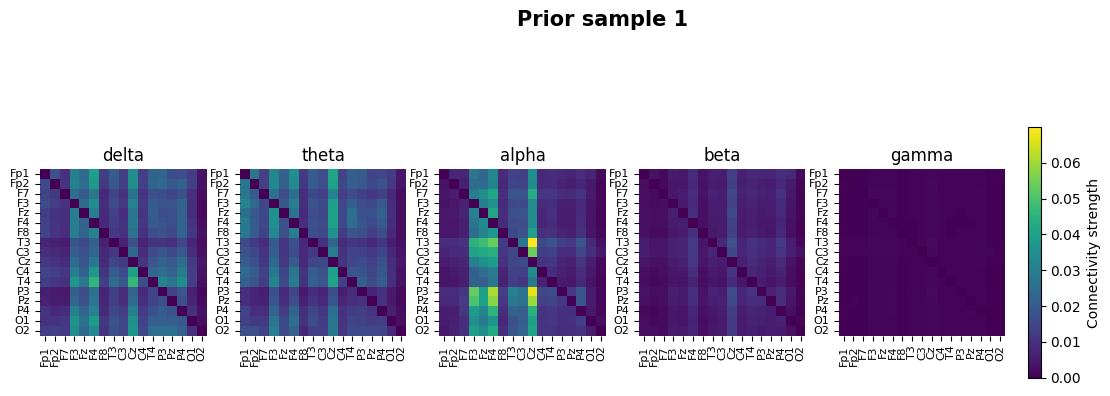

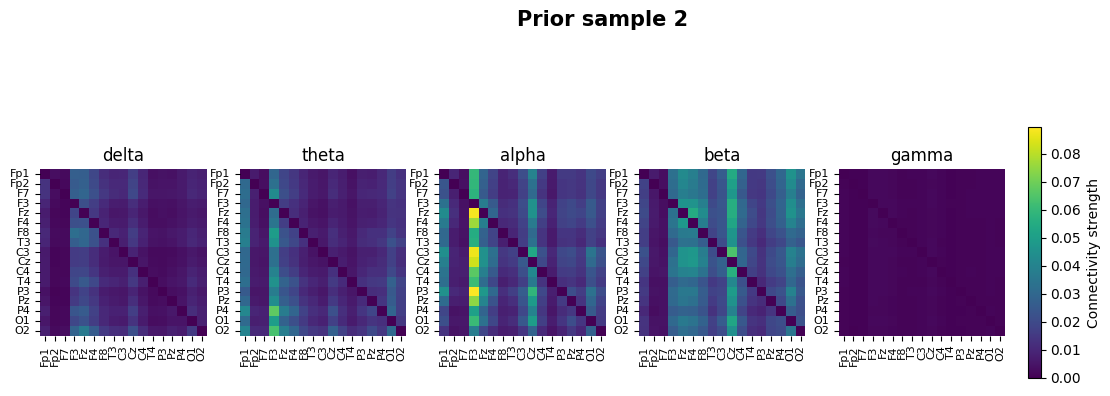

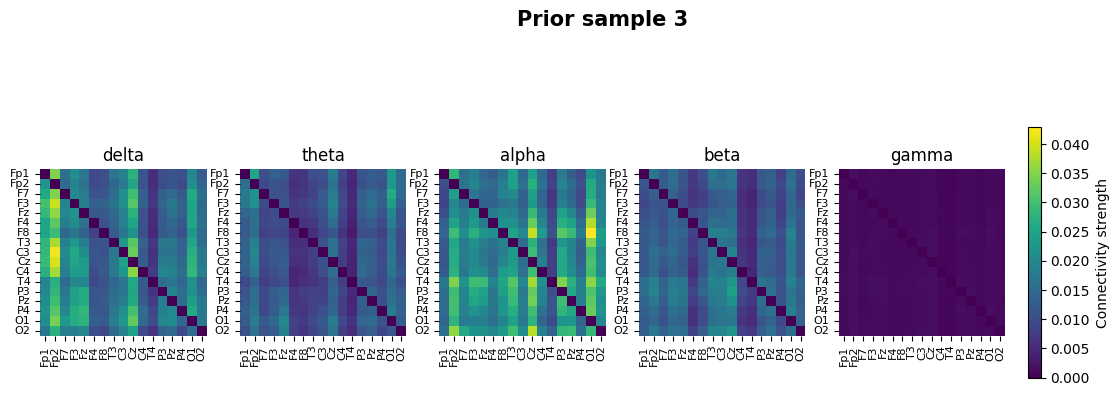

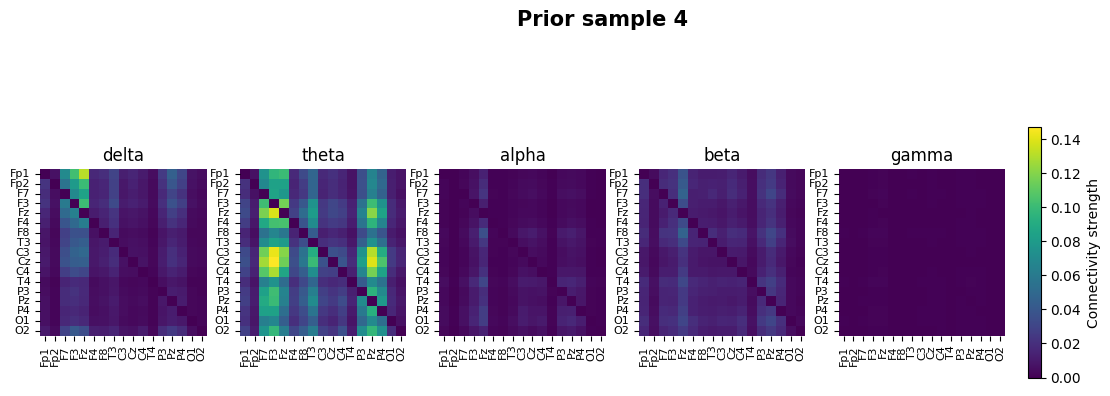

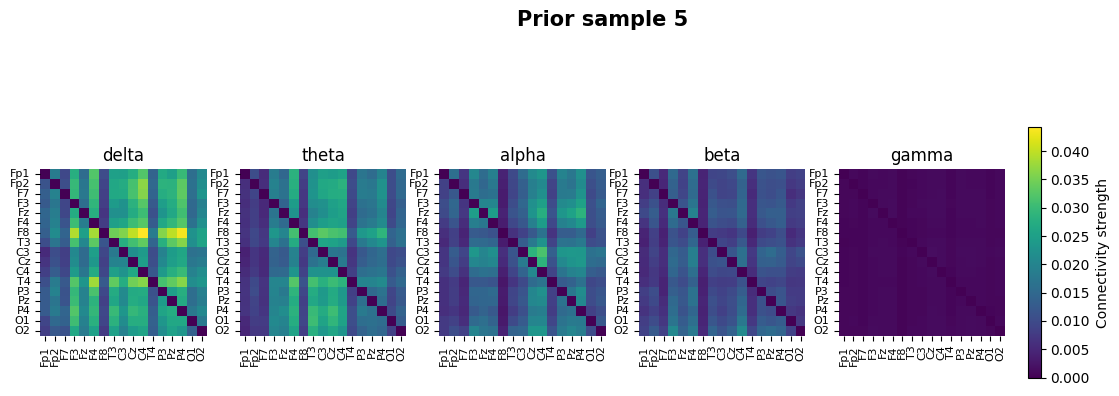

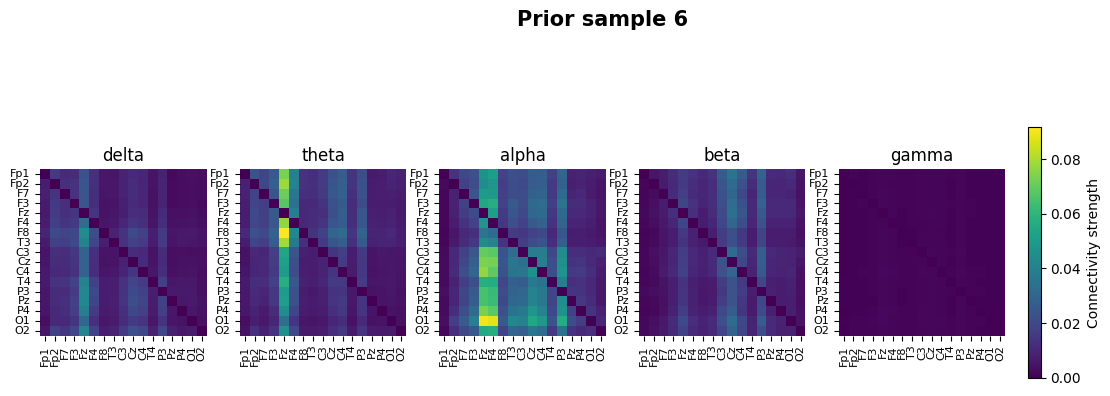

In [12]:
sample_cond = next(iter(val_loader))[2][:7].to(device)  # grab 7 real (age, sex) pairs
plot_prior_samples(model, device, num_samples=7, cond=sample_cond)